# 17 — Controlled target-formulation comparison

Results and reproduction notebook. The experiment was executed locally through `compare_target_formulations.py`; the cells below inspect the saved results. The six combinations use common historical samples and 58 input features.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'blackrock_data').exists())
out = root / 'outputs/experiments/17_target_formulations'

,candidate,family,target,development_rmse_log,development_wape,development_bias,development_log_mae,confirmation_rmse_log,confirmation_wape,confirmation_bias,mean_difference,ci_2_5,ci_97_5,rmse_change_vs_same_family_median,stable_development_years,target_change_passes_gate
0,historical_frozen_ridge,historical_reference,median20_log_residual,0.487643,0.368007,-0.143778,0.337746,0.445119,0.345631,-0.096235,NaN,NaN,NaN,NaN,NaN,NaN
1,lgbm__lag1_log_growth,lgbm,lag1_log_growth,0.470287,0.353445,-0.160621,0.330295,0.429959,0.328370,-0.096616,-0.000747,-0.001786,0.000198,0.000872,False,False
2,lgbm__log_level,lgbm,log_level,0.470677,0.356933,-0.160542,0.330397,0.430032,0.333339,-0.087199,-0.000645,-0.001812,0.000456,0.001262,False,False
3,lgbm__median20_log_residual,lgbm,median20_log_residual,0.469414,0.354518,-0.144042,0.331038,0.430646,0.329428,-0.088980,0.000000,0.000000,0.000000,0.000000,True,False
4,ridge__lag1_log_growth,ridge,lag1_log_growth,0.490633,0.374242,-0.148485,0.339166,0.448801,0.350009,-0.104211,0.001406,0.001088,0.001765,0.002855,False,False
5,ridge__log_level,ridge,log_level,0.496503,0.370598,-0.153741,0.341275,0.450372,0.349138,-0.112532,0.003515,0.003263,0.003752,0.008726,False,False
6,ridge__median20_log_residual,ridge,median20_log_residual,0.487778,0.367433,-0.145228,0.337761,0.446768,0.345088,-0.096544,0.000000,0.000000,0.000000,0.000000,True,False


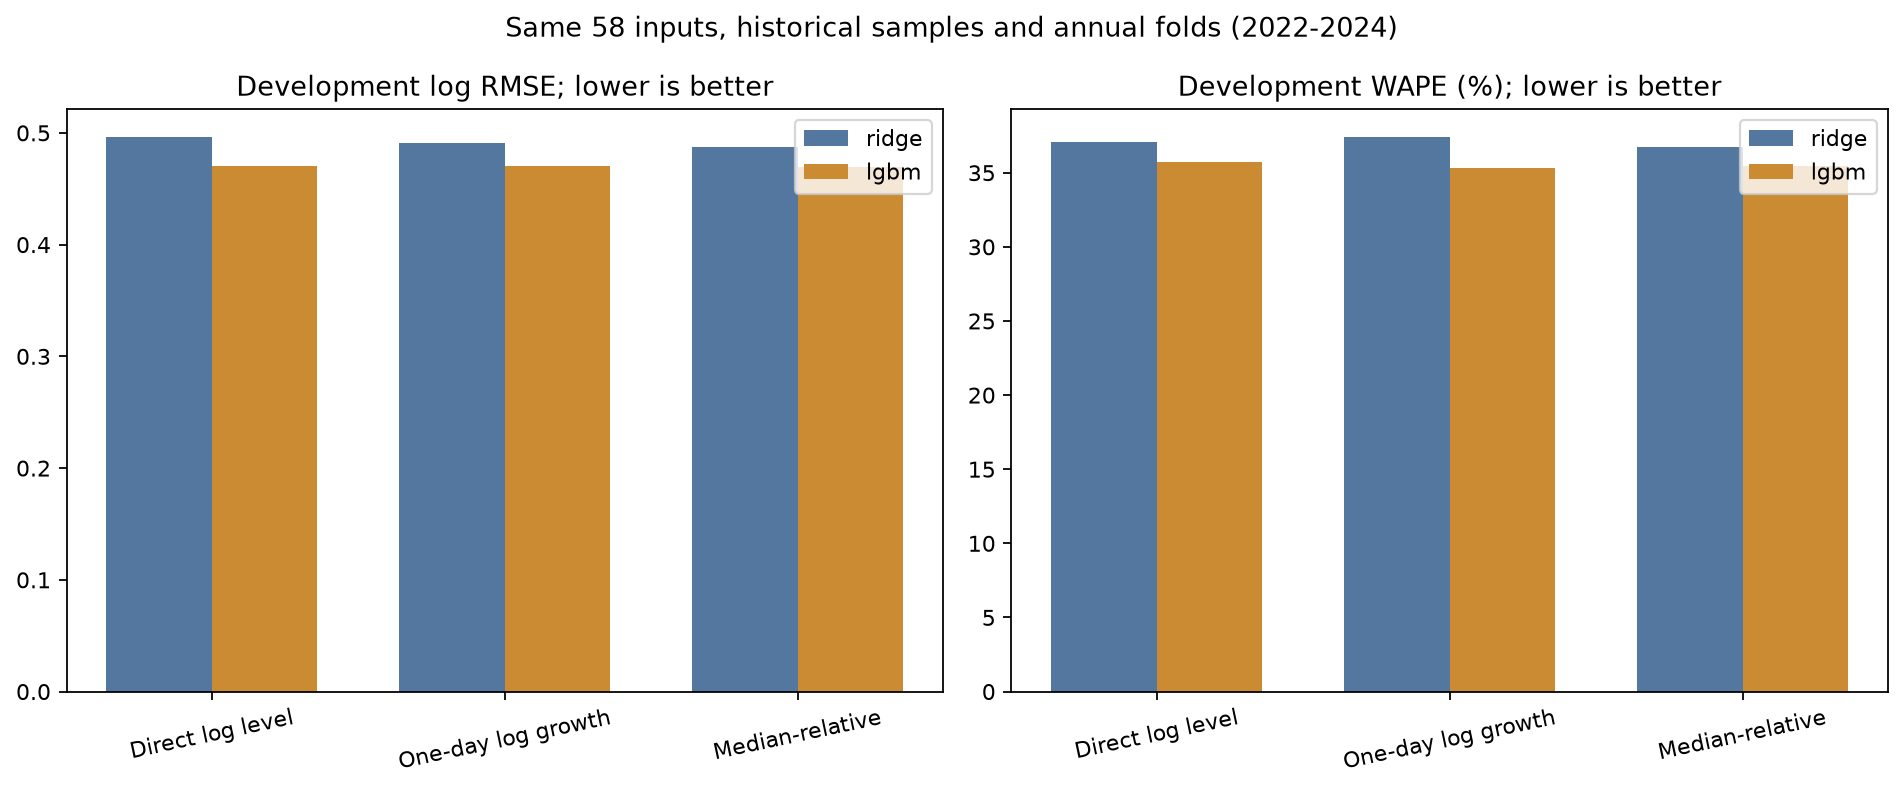

In [2]:
display(pd.read_csv(out / 'target_comparison_summary.csv'))
display(Image(filename=str(out / 'target_comparison.png')))

In [3]:
display(pd.read_csv(out / 'annual_metrics.csv'))
display(pd.read_csv(out / 'paired_target_bootstrap.csv'))

,test_year,candidate,family,target,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
0,2022,ridge__log_level,ridge,log_level,328634,74532.986257,0.382985,0.367598,0.541638,0.948810,-0.157714
1,2022,lgbm__log_level,lgbm,log_level,328634,71953.107504,0.369729,0.354708,0.512770,0.953569,-0.169646
2,2022,ridge__lag1_log_growth,ridge,lag1_log_growth,328634,75324.588959,0.387053,0.366034,0.537888,0.948689,-0.155180
3,2022,lgbm__lag1_log_growth,lgbm,lag1_log_growth,328634,71400.894608,0.366891,0.356932,0.514212,0.953359,-0.169104
4,2022,ridge__median20_log_residual,ridge,median20_log_residual,328634,74015.247422,0.380325,0.363769,0.533897,0.948930,-0.147578
5,2022,lgbm__median20_log_residual,lgbm,median20_log_residual,328634,71383.784615,0.366803,0.355622,0.510104,0.953520,-0.146629
6,2022,historical_frozen_ridge,historical_reference,median20_log_residual,328634,74158.286694,0.381060,0.363771,0.533507,0.948964,-0.144407
7,2023,ridge__log_level,ridge,log_level,318679,81896.021233,0.371747,0.338332,0.493066,0.956080,-0.148059
8,2023,lgbm__log_level,lgbm,log_level,318679,78038.713446,0.354237,0.324664,0.461805,0.960355,-0.153401
9,2023,ridge__lag1_log_growth,ridge,lag1_log_growth,318679,82522.670988,0.374591,0.335628,0.485924,0.956133,-0.144529


,candidate,reference,period,dates,mean_difference,ci_2_5,ci_97_5
0,ridge__log_level,ridge__median20_log_residual,development,753,0.003515,0.003263,0.003752
1,ridge__log_level,ridge__median20_log_residual,confirmation,250,0.002144,0.001847,0.002461
2,ridge__lag1_log_growth,ridge__median20_log_residual,development,753,0.001406,0.001088,0.001765
3,ridge__lag1_log_growth,ridge__median20_log_residual,confirmation,250,0.000953,0.000527,0.001544
4,ridge__median20_log_residual,ridge__median20_log_residual,development,753,0.000000,0.000000,0.000000
5,ridge__median20_log_residual,ridge__median20_log_residual,confirmation,250,0.000000,0.000000,0.000000
6,lgbm__log_level,lgbm__median20_log_residual,development,753,-0.000645,-0.001812,0.000456
7,lgbm__log_level,lgbm__median20_log_residual,confirmation,250,0.000266,-0.001724,0.002076
8,lgbm__lag1_log_growth,lgbm__median20_log_residual,development,753,-0.000747,-0.001786,0.000198
9,lgbm__lag1_log_growth,lgbm__median20_log_residual,confirmation,250,-0.001913,-0.003623,-0.000297


In [4]:
checks = pd.read_csv(out / 'validation_checks.csv')
assert checks.passed.all()
display(checks)

,check,passed
0,2022_unique_keys,True
1,2022_all_dates_in_year,True
2,2022_identical_labels_reference_and_cached_lgbm,True
3,2022_ridge__log_level_complete_finite_nonnegative,True
4,2022_ridge__log_level_recomputed_metrics,True
...,...,...
87,2025_ridge__lag1_log_growth_model_reconstruction,True
88,2025_ridge__median20_log_residual_model_recons...,True
89,2025_lgbm__log_level_model_reconstruction,True
90,2025_lgbm__lag1_log_growth_model_reconstruction,True


To rerun model fitting, execute `.venv/bin/python notebooks/compare_target_formulations.py` from the repository root with the step-03 OpenMP runtime environment. See the saved experiment plan and README for target definitions, fallbacks and limitations.